# Shock numbers: what the data show around each reference episode

For each episode in `data/raw/shocks/episodes.csv`, this notebook pulls the numbers worth quoting: trust, turnout, party system, economy and democratic quality, before and after the shock, next to the EU and to France today.

**These are observations, not effects or forecasts.** A change during an episode does not prove the episode caused it. Raw files are only read, never changed.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROC, RAW = ROOT / 'data/processed', ROOT / 'data/raw'
pd.set_option('display.float_format', '{:.1f}'.format)

# Reference episodes (written by the team)
episodes = pd.read_csv(RAW / 'shocks/episodes.csv')
episodes['start_date'] = pd.to_datetime(episodes.start)
episodes['end_date'] = pd.to_datetime(episodes.end) + pd.offsets.MonthEnd(0)
# Readable episode names (country and years). The short IDs (e.g. S1_BE_2010) are only used inside the code.
years = lambda r: r.start[:4] + ('' if r.start[:4] == r.end[:4] else '–' + r.end[2:4])
episodes['episode'] = [f'{r.country} {years(r)}' for r in episodes.itertuples()]
LABEL = dict(zip(episodes.episode_id, episodes.episode))

def named(df):
    # Replace episode IDs by 'Country years' in a table's index or 'episode' column.
    df = df.rename(index=LABEL)
    return df.assign(episode=df.episode.map(LABEL)) if 'episode' in df.columns else df
ISO2 = {'BEL': 'BE', 'ESP': 'ES', 'FRA': 'FR', 'GRC': 'EL', 'PRT': 'PT', 'IRL': 'IE', 'AUT': 'AT', 'ITA': 'IT'}
episodes['iso2'] = episodes.iso3.map(ISO2)

# Eurobarometer trust waves (one row per country, institution and wave)
eb = pd.read_csv(PROC / 'eurobarometer_trust_trend.csv', parse_dates=['fieldwork_start'])
eb['fieldwork_end'] = pd.to_datetime(eb.fieldwork.str.split(' ').str[1], format='%d/%b/%Y', errors='coerce')
eb = eb.groupby(['country_code', 'institution', 'wave'], as_index=False).agg(
    trust=('trust_pct', 'mean'), start=('fieldwork_start', 'first'), end=('fieldwork_end', 'first'))

# PPEG parliamentary elections (exact dates, parties and alliances)
with ZipFile(RAW / 'ppeg_2025v1/ppeg_parl_2025v1.zip') as archive:
    ppeg = pd.read_csv(archive.open('ppeg_parl_2025v1.csv'), low_memory=False)
ppeg['edate'] = pd.to_datetime(ppeg.edate)
ppeg['party'] = ppeg.pinitials.fillna(ppeg.pname_en)
# Electoral list = the alliance for alliance members, the party otherwise. PPEG sometimes gives an
# alliance's member parties (France 2022) and sometimes one alliance row (France 2024); counting
# lists makes elections comparable.
member = ppeg.alliance.eq('Electoral alliance member') & ppeg.alliance_id.notna()
ppeg['list_id'] = ppeg.alliance_id.where(member, ppeg.party_id)
ppeg['list_name'] = ppeg.alliance_initials.where(member, ppeg.party)
# When a list is renamed between two elections, follow it to its successor (documented, France only).
SUCCESSOR = {'FR603': 'FR604',   # NUPES 2022 -> New Popular Front 2024
             'FR29': 'FR606',    # RN alone 2022 -> RN et Alliés 2024
             'FR607': 'FR33',    # UDC (LR + UDI) 2022 -> LR 2024
             'BE600': 'BE30'}    # SP.A-Spirit joint list 2007 -> SP.A 2010
# Belgium: PPEG has party estimates inside the 2007 CD&V/N-VA joint list, so count by party
# (otherwise the joint list's break-up hides N-VA's rise).
COUNT_BY_PARTY = {'BEL'}
# Lists that are one political family under several names (Spain: IU -> Unidos Podemos -> Unidas Podemos),
# so a renaming is not read as one list collapsing and another surging.
FAMILY = pd.read_csv(ROOT / 'data/reference/party_lists.csv').set_index('party_id').list_family.to_dict()

macro = pd.read_csv(PROC / 'eurostat_macro_country_year.csv')
vdem = pd.read_csv(PROC / 'vdem_country_year_core_v16.csv')

episodes[['shock', 'episode', 'start', 'end', 'note']]

,shock,episode,start,end,note
0,S1,Belgium 2010–11,2010-04,2011-12,Leterme II falls Apr 2010; Di Rupo govt Dec 20...
1,S1,Spain 2015–16,2015-12,2016-10,"Hung parliament Dec 2015, repeat election Jun ..."
2,S1,France 2024–25,2024-06,2025-10,Dissolution Jun 2024 to Lecornu govt Oct 2025....
3,S2,Spain 2008–13,2008-09,2013-12,Euro area crisis; start = Lehman collapse.
4,S2,Greece 2008–13,2008-09,2013-12,Euro area crisis; most severe case.
5,S2,Portugal 2008–13,2008-09,2013-12,Euro area crisis; bailout 2011.
6,S2,Ireland 2008–13,2008-09,2013-12,Euro area crisis; bailout 2010.
7,S3,Austria 2019,2019-05,2019-09,"Ibiza video May 2019, snap election Sep 2019. ..."
8,S3,Spain 2018,2018-05,2018-06,"Gurtel verdict May 2018, Rajoy ousted Jun 2018..."
9,S3,Italy 1992–94,1992-02,1994-03,Mani pulite. Vote and party system only: no co...


## 1. Trust around each episode

For each episode and institution: the average of the two Eurobarometer waves **before** it, the **lowest** wave from its start to the first wave after its end, and that **first wave after**. The EU column shows how the EU average moved between the same waves, so a fall that Europe also saw is not mistaken for a national one.

In [2]:
INSTITUTIONS = ['National parliament', 'National government', 'Political parties']

def trust_window(ep, institution):
    d = eb[eb.institution == institution]
    country = d[d.country_code == ep.iso2].sort_values('start')
    eu = d[d.country_code == 'EU'].set_index('wave').trust
    before = country[country.end < ep.start_date].tail(2)
    after = country[country.start > ep.end_date].head(1)
    window = pd.concat([country[country.start.between(ep.start_date, ep.end_date)], after])
    if len(before) < 2 or window.empty:
        return None
    low = window.loc[window.trust.idxmin()]
    return {'shock': ep.shock, 'episode': ep.episode_id, 'institution': institution,
            'before': before.trust.mean(), 'lowest': low.trust, 'lowest_wave': f'{low.start:%b %Y}',
            'first_after_end': after.trust.iloc[0] if len(after) else float('nan'),
            'change_to_lowest': low.trust - before.trust.mean(),
            'eu_change_same_waves': eu.get(low.wave) - eu.reindex(before.wave).mean()}

trust = pd.DataFrame([row for ep in episodes[episodes.use_trust == 1].itertuples()
                      for inst in INSTITUTIONS if (row := trust_window(ep, inst))])
trust['beyond_eu'] = trust.change_to_lowest - trust.eu_change_same_waves
named(trust)

,shock,episode,institution,before,lowest,lowest_wave,first_after_end,change_to_lowest,eu_change_same_waves,beyond_eu
0,S1,Belgium 2010–11,National parliament,39.5,28.0,May 2010,46.0,-11.5,0.0,-11.5
1,S1,Belgium 2010–11,National government,35.5,22.0,May 2010,44.0,-13.5,-1.5,-12.0
2,S1,Belgium 2010–11,Political parties,24.5,20.0,May 2010,32.0,-4.5,0.5,-5.0
3,S1,Spain 2015–16,National parliament,11.0,15.0,May 2016,17.0,4.0,-3.0,7.0
4,S1,Spain 2015–16,National government,14.0,14.0,May 2016,20.0,0.0,-5.0,5.0
5,S1,Spain 2015–16,Political parties,6.0,6.0,May 2016,10.0,0.0,0.5,-0.5
6,S1,France 2024–25,National parliament,27.0,12.0,Oct 2025,23.0,-15.0,-3.5,-11.5
7,S1,France 2024–25,National government,22.5,9.0,Oct 2025,21.0,-13.5,-1.5,-12.0
8,S1,France 2024–25,Political parties,9.0,7.0,Oct 2025,12.0,-2.0,5.0,-7.0
9,S2,Spain 2008–13,National parliament,50.5,7.0,May 2013,9.0,-43.5,-8.5,-35.0


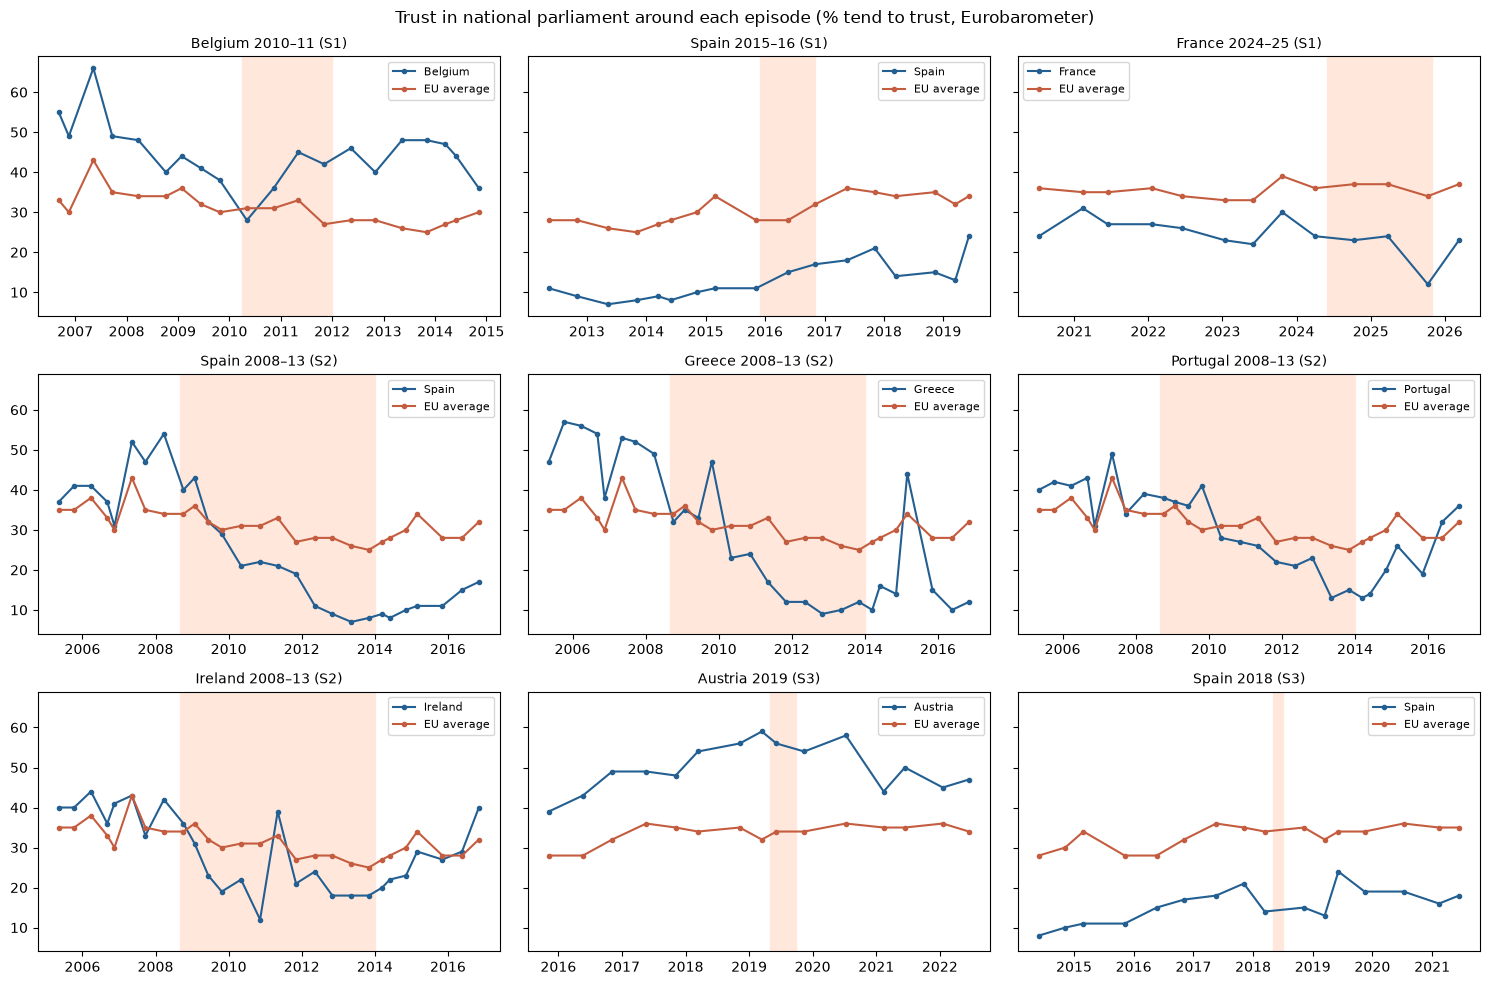

In [3]:
eps = episodes[episodes.use_trust == 1]
parliament = eb[eb.institution == 'National parliament']
fig, axes = plt.subplots(3, 3, figsize=(15, 10), sharey=True)
for ax, ep in zip(axes.flat, eps.itertuples()):
    lo, hi = ep.start_date - pd.DateOffset(years=4), ep.end_date + pd.DateOffset(years=3)
    for code, label, color in [(ep.iso2, ep.country, '#245f91'), ('EU', 'EU average', '#c45d3f')]:
        s = parliament[(parliament.country_code == code) & parliament.start.between(lo, hi)].sort_values('start')
        ax.plot(s.start, s.trust, marker='o', ms=3, color=color, label=label)
    ax.axvspan(ep.start_date, ep.end_date, color='#ffe7dc')
    ax.set_title(f'{LABEL[ep.episode_id]} ({ep.shock})', fontsize=10)
    ax.legend(fontsize=8)
fig.suptitle('Trust in national parliament around each episode (% tend to trust, Eurobarometer)')
plt.tight_layout()

## 2. France today against the episodes

Where France's latest trust level sits relative to the reference countries' levels before their shocks, and the lowest levels they reached.

In [4]:
france_now = eb[eb.country_code == 'FR'].sort_values('start').groupby('institution').tail(1).set_index('institution')
france = trust.groupby('institution').agg(lowest_start=('before', 'min'), highest_start=('before', 'max'),
                                         lowest_point_seen=('lowest', 'min'))
france['france_now'] = france_now.trust
france['france_wave'] = france_now.start.dt.strftime('%b %Y')
france.rename(columns={'lowest_start': 'reference countries: lowest start', 'highest_start': 'reference countries: highest start',
                       'lowest_point_seen': 'reference countries: lowest point', 'france_now': 'France now', 'france_wave': 'France wave'})

,reference countries: lowest start,reference countries: highest start,reference countries: lowest point,France now,France wave
institution,,,,,
National government,14.0,55.5,6.0,21.0,Mar 2026
National parliament,11.0,57.5,7.0,23.0,Mar 2026
Political parties,6.0,37.0,4.0,12.0,Mar 2026


## 3. Turnout and the party system

Elections from PPEG: the last election before each episode and every election during it (or up to 12 months after it ends). **Effective number of parties** (1 / sum of squared vote shares) measures fragmentation: higher means votes are spread over more parties. When one of the compared elections reports a sizeable alliance (5%+ of the vote) only as a single row, with votes not split by party (e.g. France 2024), both elections are counted **by electoral list** so they stay comparable; otherwise by party (`counted_by` column). "Others" rows count as one. Turnout is left blank for Belgium (compulsory voting) and where `episodes.csv` excludes it.

In [5]:
def election_table(iso3):
    d = ppeg[ppeg.iso3c == iso3]
    enp = lambda key: d.groupby(['edate', key]).v_share.sum().groupby(level='edate').apply(lambda s: 1 / (s ** 2).sum())
    g = d.groupby('edate').agg(electorate=('electorate', 'first'), total_vote=('total_vote', 'first'))
    g['parties_enp'], g['lists_enp'] = enp('party_id'), enp('list_id')
    g['turnout'] = g.total_vote / g.electorate * 100
    return g

def by_list_needed(iso3, dates):
    # True when a sizeable alliance (5%+ of the vote) appears only as one row, with no party split.
    if iso3 in COUNT_BY_PARTY:
        return False
    d = ppeg[(ppeg.iso3c == iso3) & ppeg.edate.isin(dates)]
    return bool((d.alliance.eq('Electoral alliance') & d.v_share.ge(0.05)).any())

rows = []
for ep in episodes.itertuples():
    g = election_table(ep.iso3)
    before = g[g.index < ep.start_date].tail(1)
    during = g[(g.index >= ep.start_date) & (g.index <= ep.end_date + pd.DateOffset(months=12))]
    by_list = by_list_needed(ep.iso3, list(before.index) + list(during.index))
    for role, part in [('before', before), ('during', during)]:
        for date, r in part.iterrows():
            rows.append({'shock': ep.shock, 'episode': ep.episode_id, 'role': role, 'election': f'{date:%b %Y}',
                         'turnout': r.turnout if ep.use_turnout else float('nan'),
                         'fragmentation': r.lists_enp if by_list else r.parties_enp, 'counted_by': 'list' if by_list else 'party'})
elections = pd.DataFrame(rows)
named(elections)

,shock,episode,role,election,turnout,fragmentation,counted_by
0,S1,Belgium 2010–11,before,Jun 2007,NaN,9.9,party
1,S1,Belgium 2010–11,during,Jun 2010,NaN,9.9,party
2,S1,Spain 2015–16,before,Nov 2011,68.9,3.3,list
3,S1,Spain 2015–16,during,Dec 2015,69.7,5.7,list
4,S1,Spain 2015–16,during,Jun 2016,66.5,5.0,list
5,S1,France 2024–25,before,Jun 2022,47.5,5.4,list
6,S1,France 2024–25,during,Jun 2024,66.7,4.1,list
7,S2,Spain 2008–13,before,Mar 2008,73.8,2.8,list
8,S2,Spain 2008–13,during,Nov 2011,68.9,3.3,list
9,S2,Greece 2008–13,before,Sep 2007,74.2,3.0,list


In [6]:
# Change from the election before to the last one during the episode
first_last = elections.groupby('episode').agg(
    shock=('shock', 'first'), from_election=('election', 'first'), to_election=('election', 'last'),
    turnout_change=('turnout', lambda s: s.iloc[-1] - s.iloc[0]),
    fragmentation_change=('fragmentation', lambda s: s.iloc[-1] - s.iloc[0]), counted_by=('counted_by', 'first'))
named(first_last)

,shock,from_election,to_election,turnout_change,fragmentation_change,counted_by
episode,,,,,,
Belgium 2010–11,S1,Jun 2007,Jun 2010,NaN,0.1,party
Spain 2015–16,S1,Nov 2011,Jun 2016,-2.5,1.7,list
France 2024–25,S1,Jun 2022,Jun 2024,19.2,-1.3,list
Spain 2008–13,S2,Mar 2008,Nov 2011,-4.9,0.5,list
Greece 2008–13,S2,Sep 2007,Jun 2012,-11.7,2.1,list
Ireland 2008–13,S2,May 2007,Feb 2011,2.9,0.7,party
Portugal 2008–13,S2,Feb 2005,Jun 2011,-6.2,0.5,party
Austria 2019,S3,Oct 2017,Sep 2019,NaN,0.1,party
Spain 2018,S3,Jun 2016,Apr 2019,NaN,1.1,list


In [7]:
# Which parties (or lists, see above) gained and lost most between those two elections (vote share, points)
def movers(ep, n=3):
    d = ppeg[ppeg.iso3c == ep.iso3]
    dates = sorted(d.edate.unique())
    before = [x for x in dates if x < ep.start_date][-1]
    after = [x for x in dates if ep.start_date <= x <= ep.end_date + pd.DateOffset(months=12)][-1]
    key, label = ('list_id', 'list_name') if by_list_needed(ep.iso3, [before, after]) else ('party_id', 'party')
    names = d.sort_values('edate').groupby(key)[label].last()
    group = d[key].replace(SUCCESSOR)
    group = group.map(lambda i: FAMILY.get(i, i) if ep.iso3 != 'FRA' else i)  # France: NUPES -> NFP already linked by SUCCESSOR
    share = lambda date: d[d.edate == date].groupby(group).v_share.sum() * 100
    diff = share(after).sub(share(before), fill_value=0).drop(index=[i for i in names.index if str(i).endswith('999')], errors='ignore')
    fmt = lambda s: ', '.join(f'{names.get(i, i)} {v:+.1f}' for i, v in s.items())
    return {'episode': ep.episode_id, 'elections': f'{before:%Y} → {after:%b %Y}',
            'biggest_gains': fmt(diff.nlargest(n)), 'biggest_losses': fmt(diff.nsmallest(n))}

party_moves = pd.DataFrame([movers(ep) for ep in episodes.itertuples()])
named(party_moves)

,episode,elections,biggest_gains,biggest_losses
0,Belgium 2010–11,2007 → Jun 2010,"N-VA +14.3, PS +2.8, PP +1.3","CD&V -4.6, VB -4.2, MR -3.2"
1,Spain 2015–16,2011 → Jun 2016,"Podemos–IU and allies +14.1, C's +13.1, CDC +2.0","PP -12.2, PSOE -6.5, UPyD -4.6"
2,France 2024–25,2022 → Jun 2024,"RN et Alliés +14.5, DVD +3.6, NFP +2.5","LR -4.7, Ensemble -4.5, R -3.5"
3,Spain 2008–13,2008 → Nov 2011,"PP +5.3, UPyD +3.6, Podemos–IU and allies +3.3","PSOE -14.7, CA -0.3, EA -0.2"
4,Greece 2008–13,2007 → Jun 2012,"SYRIZA +21.8, ANEL +7.5, XA +6.9","PASOK -25.8, ND -12.2, KKE -3.7"
5,Portugal 2008–13,2005 → Jun 2011,"PSD +10.7, CDS-PP +4.7, PAN +1.1","PSP -17.2, BE -1.1, ID -1.1"
6,Ireland 2008–13,2007 → Feb 2011,"ILP +9.3, FG +8.8, Independents/Non-Partisans ...","FF -24.1, GP -2.8, PD -2.7"
7,Austria 2019,2017 → Sep 2019,"Grüne +10.1, ÖVP +6.0, NEOS +2.8","FPÖ -9.8, SPÖ -5.7, JETZT -2.5"
8,Spain 2018,2016 → Apr 2019,"VOX +10.1, PSOE +6.3, C's +2.9","PP -16.2, Podemos–IU and allies -6.7, CDC -2.0"
9,Italy 1992–94,1987 → Mar 1994,"FI +21.0, LN +8.4, AN +7.6","PPI -23.2, SI -12.1, DS -6.2"


## 4. Economy during the financial crisis (S2)

Eurostat figures for the S2 countries, the EU-27 and France: the worst growth year, the unemployment peak against 2007, and public debt before and after. Unemployment before 2009 comes from Eurostat's historical series (`une_rt_a_h`), because the current one starts in 2009 for most countries; see the `une_rt_a_unemployment_source` column. The last rows show France's latest values for comparison.

In [8]:
GEO = {'ES': 'Spain', 'EL': 'Greece', 'PT': 'Portugal', 'IE': 'Ireland', 'FR': 'France', 'EU27_2020': 'EU-27'}
crisis = {}
for geo, name in GEO.items():
    g = macro[macro.geo == geo].set_index('year')
    w = g.loc[2008:2014]
    crisis[name] = {'worst_gdp_growth': w.nama_10_gdp_real_growth.min(), 'worst_year': w.nama_10_gdp_real_growth.idxmin(),
                    # This Eurostat download starts unemployment in 2009 for most S2 countries: use the first year available.
                    'unemployment_first_year': g.une_rt_a_unemployment.loc[2007:].first_valid_index(),
                    'unemployment_first': g.une_rt_a_unemployment.loc[2007:].dropna().iloc[0], 'unemployment_peak': w.une_rt_a_unemployment.max(),
                    'debt_2007': g.gov_10dd_edpt1_debt_gdp.get(2007), 'debt_2013': g.gov_10dd_edpt1_debt_gdp.get(2013)}
crisis = pd.DataFrame(crisis).T
crisis[['worst_year', 'unemployment_first_year']] = crisis[['worst_year', 'unemployment_first_year']].astype('Int64')
fr = macro[macro.geo == 'FR'].set_index('year')
latest = pd.DataFrame({'year': [int(fr[c].dropna().index[-1]) for c in ['nama_10_gdp_real_growth', 'une_rt_a_unemployment', 'gov_10dd_edpt1_debt_gdp']],
                       'France latest': [fr[c].dropna().iloc[-1] for c in ['nama_10_gdp_real_growth', 'une_rt_a_unemployment', 'gov_10dd_edpt1_debt_gdp']]},
                      index=['GDP growth %', 'Unemployment %', 'Public debt % GDP'])
display(crisis)
latest

,worst_gdp_growth,worst_year,unemployment_first_year,unemployment_first,unemployment_peak,debt_2007,debt_2013
Spain,-3.8,2009,2007,8.2,26.1,35.7,100.0
Greece,-9.9,2011,2007,8.4,27.8,104.6,180.4
Portugal,-4.1,2012,2007,8.1,17.2,72.7,130.8
Ireland,-5.1,2009,2007,5.0,15.5,24.0,117.8
France,-2.8,2009,2007,8.0,10.3,65.5,94.6
EU-27,-4.3,2009,2007,7.5,11.6,62.4,86.8


,year,France latest
GDP growth %,2025,0.8
Unemployment %,2025,7.7
Public debt % GDP,2025,115.7


## 5. Democratic quality (V-Dem)

Electoral democracy index the year before each episode and the year after it ends, with V-Dem's uncertainty interval. A change smaller than the interval is not a clear change.

In [9]:
v = vdem.set_index(['country_text_id', 'year'])
rows = []
for ep in episodes.itertuples():
    y0, y1 = ep.start_date.year - 1, min(ep.end_date.year + 1, int(vdem.year.max()))
    if (ep.iso3, y0) not in v.index or (ep.iso3, y1) not in v.index:
        continue
    a, b = v.loc[(ep.iso3, y0)], v.loc[(ep.iso3, y1)]
    rows.append({'episode': ep.episode_id, 'year_before': y0, 'before': a.v2x_polyarchy, 'year_after': y1,
                 'after': b.v2x_polyarchy, 'change': b.v2x_polyarchy - a.v2x_polyarchy,
                 'interval_width_after': b.v2x_polyarchy_codehigh - b.v2x_polyarchy_codelow})
vdem_changes = pd.DataFrame(rows)
named(vdem_changes).style.format(precision=3).hide(axis='index')

episode,year_before,before,year_after,after,change,interval_width_after
Belgium 2010–11,2009,0.899,2012,0.900,0.001,0.067
Spain 2015–16,2014,0.871,2017,0.835,-0.036,0.084
France 2024–25,2023,0.871,2025,0.865,-0.006,0.086
Spain 2008–13,2007,0.876,2014,0.871,-0.005,0.076
Greece 2008–13,2007,0.895,2014,0.889,-0.006,0.066
Portugal 2008–13,2007,0.894,2014,0.886,-0.008,0.074
Ireland 2008–13,2007,0.891,2014,0.895,0.004,0.072
Austria 2019,2018,0.851,2020,0.858,0.007,0.085
Spain 2018,2017,0.835,2019,0.871,0.036,0.075


## 6. Summary of findings

Written from the tables above, so it updates with the data. Check the table behind a number before quoting it.

In [10]:
from IPython.display import Markdown

label = {r.episode_id: f"{r.country} {r.start[:4]}" + ('' if r.start[:4] == r.end[:4] else f"–{r.end[2:4]}")
         for r in episodes.itertuples()}
parl = trust[trust.institution == 'National parliament'].set_index('episode')
moves = party_moves.set_index('episode')
first = lambda text: text.split(', ')[0]

def episode_line(ep_id):
    bits = []
    if ep_id in parl.index:
        r = parl.loc[ep_id]
        after = '' if pd.isna(r.first_after_end) else f" → {r.first_after_end:.0f}% after"
        if r.lowest < r.before:
            bits.append(f"trust in parliament {r.before:.0f}% → low {r.lowest:.0f}% ({r.lowest_wave}){after} "
                        f"({r.beyond_eu:+.0f} pts vs EU trend)")
        else:
            bits.append(f"trust in parliament {r.before:.0f}% before, no fall during the episode{after}")
    e = first_last.loc[ep_id]
    if pd.notna(e.turnout_change):
        bits.append(f"turnout {e.turnout_change:+.1f} pts")
    bits.append(f"fragmentation {e.fragmentation_change:+.1f}")
    bits.append(f"biggest gain {first(moves.loc[ep_id, 'biggest_gains'])}, biggest loss {first(moves.loc[ep_id, 'biggest_losses'])}")
    return f"- **{label[ep_id]}** ({e.from_election} → {e.to_election} elections): " + '; '.join(bits) + '.'

def trust_pattern(shock):
    p = parl[parl.shock == shock]
    if p.empty:
        return 'No Eurobarometer trust data for these episodes.'
    fell = (p.beyond_eu <= -3).sum()
    recovered = (p.first_after_end > p.lowest).sum()
    return (f"Trust in parliament fell at least 3 points beyond the EU trend in **{fell} of {len(p)}** episodes "
            f"(from {p.beyond_eu.max():+.0f} to {p.beyond_eu.min():+.0f} pts). "
            f"It was back above its low at the first reading after the episode in {recovered} of {len(p)}.")

TITLES = {'S1': 'S1 · Government collapse and deadlock', 'S2': 'S2 · Systemic financial crisis', 'S3': 'S3 · Integrity scandal at the top'}
out = []
for shock, title in TITLES.items():
    out += [f"### {title}", trust_pattern(shock)]
    if shock == 'S2':
        c = crisis.loc[['Spain', 'Greece', 'Portugal', 'Ireland']]
        out.append(f"Economy ({', '.join(c.index)}): unemployment went from {c.unemployment_first.min():.0f}–{c.unemployment_first.max():.0f}% in 2007 "
                   f"to peaks of {c.unemployment_peak.min():.0f}–{c.unemployment_peak.max():.0f}%; public debt from "
                   f"{c.debt_2007.min():.0f}–{c.debt_2007.max():.0f}% to {c.debt_2013.min():.0f}–{c.debt_2013.max():.0f}% of GDP (2013).")
    out += [''] + [episode_line(e) for e in episodes[episodes.shock == shock].episode_id] + ['']

fp, fg = france.loc['National parliament'], france.loc['National government']
starts = parl.drop(index='S1_FR_2024').before  # other countries only
debt, unemp = latest.loc['Public debt % GDP'], latest.loc['Unemployment %']
c = crisis.loc[['Spain', 'Greece', 'Portugal', 'Ireland']]
fr_s1 = parl.loc['S1_FR_2024']
v = vdem_changes
out += ["### France today",
        f"- **Trust is already low:** {fp.france_now:.0f}% trust parliament and {fg.france_now:.0f}% the government ({fp.france_wave}). "
        f"Only {(starts < fp.france_now).sum()} of {len(starts)} reference countries started lower before their shock; "
        f"the lowest level any of them reached was {fp.lowest_point_seen:.0f}%.",
        f"- **France has just lived an S1 episode:** trust in parliament went {fr_s1.before:.0f}% → {fr_s1.lowest:.0f}% "
        f"({fr_s1.lowest_wave}) → {fr_s1.first_after_end:.0f}%, a fall {fr_s1.beyond_eu:+.0f} pts beyond the EU trend.",
        f"- **Public finances:** debt is {debt['France latest']:.0f}% of GDP ({debt.year:.0f}), above the 2007 level of every S2 country (Spain, Greece, Portugal, Ireland) "
        f"({c.debt_2007.min():.0f}–{c.debt_2007.max():.0f}%); unemployment is {unemp['France latest']:.1f}%, "
        f"close to their 2007 levels ({c.unemployment_first.min():.0f}–{c.unemployment_first.max():.0f}%).",
        f"- **Democratic quality is stable:** in {(v.change.abs() < v.interval_width_after).sum()} of {len(v)} episodes the V-Dem index "
        f"moved less than the width of its uncertainty interval, so these shocks show up in trust and votes, not in V-Dem.",
        "",
        "### What these numbers cannot show",
        "- They are **observations around 2–4 episodes per shock**, not measured effects and not forecasts for France.",
        "- Each Eurobarometer wave has about ±3 points of sampling error; a single-wave low can be noise.",
        "- Turnout and party changes are not corrected for Europe-wide trends, because elections fall on different dates."]
Markdown('\n'.join(out))

### S1 · Government collapse and deadlock
Trust in parliament fell at least 3 points beyond the EU trend in **2 of 3** episodes (from +7 to -12 pts). It was back above its low at the first reading after the episode in 3 of 3.

- **Belgium 2010–11** (Jun 2007 → Jun 2010 elections): trust in parliament 40% → low 28% (May 2010) → 46% after (-11 pts vs EU trend); fragmentation +0.1; biggest gain N-VA +14.3, biggest loss CD&V -4.6.
- **Spain 2015–16** (Nov 2011 → Jun 2016 elections): trust in parliament 11% before, no fall during the episode → 17% after; turnout -2.5 pts; fragmentation +1.7; biggest gain Podemos–IU and allies +14.1, biggest loss PP -12.2.
- **France 2024–25** (Jun 2022 → Jun 2024 elections): trust in parliament 27% → low 12% (Oct 2025) → 23% after (-12 pts vs EU trend); turnout +19.2 pts; fragmentation -1.3; biggest gain RN et Alliés +14.5, biggest loss LR -4.7.

### S2 · Systemic financial crisis
Trust in parliament fell at least 3 points beyond the EU trend in **4 of 4** episodes (from -15 to -35 pts). It was back above its low at the first reading after the episode in 3 of 4.
Economy (Spain, Greece, Portugal, Ireland): unemployment went from 5–8% in 2007 to peaks of 16–28%; public debt from 24–105% to 100–180% of GDP (2013).

- **Spain 2008–13** (Mar 2008 → Nov 2011 elections): trust in parliament 50% → low 7% (May 2013) → 9% after (-35 pts vs EU trend); turnout -4.9 pts; fragmentation +0.5; biggest gain PP +5.3, biggest loss PSOE -14.7.
- **Greece 2008–13** (Sep 2007 → Jun 2012 elections): trust in parliament 50% → low 9% (Nov 2012) → 10% after (-35 pts vs EU trend); turnout -11.7 pts; fragmentation +2.1; biggest gain SYRIZA +21.8, biggest loss PASOK -25.8.
- **Portugal 2008–13** (Feb 2005 → Jun 2011 elections): trust in parliament 36% → low 13% (May 2013) → 13% after (-15 pts vs EU trend); turnout -6.2 pts; fragmentation +0.5; biggest gain PSD +10.7, biggest loss PSP -17.2.
- **Ireland 2008–13** (May 2007 → Feb 2011 elections): trust in parliament 38% → low 12% (Nov 2010) → 20% after (-22 pts vs EU trend); turnout +2.9 pts; fragmentation +0.7; biggest gain ILP +9.3, biggest loss FF -24.1.

### S3 · Integrity scandal at the top
Trust in parliament fell at least 3 points beyond the EU trend in **2 of 2** episodes (from -3 to -4 pts). It was back above its low at the first reading after the episode in 0 of 2.

- **Austria 2019** (Oct 2017 → Sep 2019 elections): trust in parliament 58% → low 54% (Nov 2019) → 54% after (-4 pts vs EU trend); fragmentation +0.1; biggest gain Grüne +10.1, biggest loss FPÖ -9.8.
- **Spain 2018** (Jun 2016 → Apr 2019 elections): trust in parliament 18% → low 15% (Nov 2018) → 15% after (-3 pts vs EU trend); fragmentation +1.1; biggest gain VOX +10.1, biggest loss PP -16.2.
- **Italy 1992–94** (Jun 1987 → Mar 1994 elections): fragmentation +2.9; biggest gain FI +21.0, biggest loss PPI -23.2.

### France today
- **Trust is already low:** 23% trust parliament and 21% the government (Mar 2026). Only 2 of 8 reference countries started lower before their shock; the lowest level any of them reached was 7%.
- **France has just lived an S1 episode:** trust in parliament went 27% → 12% (Oct 2025) → 23%, a fall -12 pts beyond the EU trend.
- **Public finances:** debt is 116% of GDP (2025), above the 2007 level of every S2 country (Spain, Greece, Portugal, Ireland) (24–105%); unemployment is 7.7%, close to their 2007 levels (5–8%).
- **Democratic quality is stable:** in 9 of 9 episodes the V-Dem index moved less than the width of its uncertainty interval, so these shocks show up in trust and votes, not in V-Dem.

### What these numbers cannot show
- They are **observations around 2–4 episodes per shock**, not measured effects and not forecasts for France.
- Each Eurobarometer wave has about ±3 points of sampling error; a single-wave low can be noise.
- Turnout and party changes are not corrected for Europe-wide trends, because elections fall on different dates.

## Caveats

- Eurobarometer, CEVIPOF and EVS ask different trust questions; this notebook uses Eurobarometer only, so countries and years are comparable.
- Each Eurobarometer wave has sampling error of roughly ±3 points per country; one-wave dips are fragile.
- PPEG alliance rows hide their member parties (e.g. France's New Popular Front in 2024), so party-level shifts inside an alliance are not visible; renamed French lists are linked with `SUCCESSOR`.
- Italy 1992–94 predates the Eurobarometer series used here, so it appears only in the election tables.